<h1 style="background: linear-gradient(to right, #395761, #7799B6);
           color: white;
           padding: 22px;
           border-left: 10px solid #CEEB13;
           text-align: center;
           font-family: 'Roboto Mono', Menlo, 'Courier New', monospace;
           font-weight: 600;">
  Inference-Time Scaling: Scoring and Self-Refinement
</h1>


The weights stay frozen for one more notebook. The previous one sampled several solutions and let them vote. This one asks a different question of the same model: given one solution, can we tell how good it is *without* the reference answer, and can the model make it better? Both need a **score**, and the score we build here, the model's confidence in its own tokens, is also the quantity that reinforcement learning will push on in the training notebooks.

By the end of this notebook you will:

1. Write a rule-based score that looks only at the shape of a response,
2. Read the probabilities a model assigns to its own tokens and turn them into a confidence score,
3. Use a score to pick the best of several sampled solutions,
4. Have the model critique and rewrite its own answer, with a score deciding whether to keep the rewrite,
5. Measure all of it with the MATH-500 harness from the math verifier notebook.

Every function that scores or refines a response is written here. The charts come from `reasoning_utils/plots.py`.

## `Step 1`: The third lever needs a judge

Self-consistency never looks inside a chain. It counts final answers and trusts the crowd. The third inference-time lever, **critique and revise**, works on a single chain: the model reads its own solution, points out what is wrong, and writes a new one. That raises a question the vote never had to face: is the new solution better than the old one? To answer it at inference time we need a score that works *without* the reference answer, because at inference time there is none.

<div align="center"><img src="assets/scoring.svg" alt="Three ways to score a response: a rule-based score reads the shape of the text, a confidence score reads the probabilities the model assigned to its own tokens, and the math verifier compares against a reference answer; the first two need no reference and can run at inference time, the verifier is the benchmark judge and later the reward" width="1000"/></div>

| Score | Looks at | Needs the reference? | Used for |
|---|---|---|---|
| rule-based | the shape of the text: a boxed answer, its length | no | a cheap first filter |
| **confidence** | the probabilities the model gave its own tokens | no | ranking samples, gating a rewrite |
| verifier | the final answer against the reference | yes | the benchmark, and later the RL reward |

The first two are the subject of this notebook. The verifier stays what it was: the judge of the whole experiment.

## `Step 2`: Setup

The same base model, [Qwen3-0.6B-Base](https://huggingface.co/Qwen/Qwen3-0.6B-Base), compiled. `generate_text` is the sampling loop from the previous notebook, `COT_PROMPT` the template that asks for the work.

In [1]:
import math

import torch

from reasoning_utils import (
    COT_PROMPT,
    MATH_PROMPT,
    evaluate_math,
    extract_final_answer,
    generate_text,
    get_device,
    grade,
    last_boxed,
    load_math500,
    load_qwen3,
    render_math_prompt,
)
from reasoning_utils.plots import (
    plot_accuracy_comparison,
    plot_brevity_bonus,
    plot_logits_to_logprobs,
    plot_token_logprobs,
)
from reasoning_utils.verify import NUMBER

device = get_device()
model, tokenizer = load_qwen3("base", device=device, compile=True)

device: cuda (NVIDIA L40S)


The running example is the rectangle problem again, answer 126, with the step-by-step prompt. Two sampled solutions to compare throughout:

In [2]:
problem = "A rectangle's length is 4 more than twice its width. Its perimeter is 50. What is its area?"
answer = "126"

prompt = render_math_prompt(problem, MATH_PROMPT)
prompt_cot = render_math_prompt(problem, COT_PROMPT)

In [3]:
torch.manual_seed(2)
solution_a = generate_text(model, tokenizer, prompt_cot, device, max_new_tokens=600, stream=True, temperature=0.8, top_p=0.9)

 Let's solve the problem step by step.

**Step 1: Define the variables**

Let \( w \) be the width of the rectangle. Then, the length \( l \) of the rectangle is given by:
\[ l = 2w + 4 \]

**Step 2: Use the perimeter formula**

The perimeter \( P \) of a rectangle is given by:
\[ P = 2(l + w) \]
Given that the perimeter is 50, we can write:
\[ 2(l + w) = 50 \]

**Step 3: Substitute the expression for length**

Substitute \( l = 2w + 4 \) into the perimeter equation:
\[ 2((2w + 4) + w) = 50 \]
\[ 2(3w + 4) = 50 \]
\[ 6w + 8 = 50 \]

**Step 4: Solve for \( w \)**

Subtract 8 from both sides:
\[ 6w = 42 \]
Divide both sides by 6:
\[ w = 7 \]

**Step 5: Find the length \( l \)**

Using the expression for length:
\[ l = 2w + 4 \]
\[ l = 2(7) + 4 \]
\[ l = 14 + 4 \]
\[ l = 18 \]

**Step 6: Calculate the area**

The area \( A \) of a rectangle is given by:
\[ A = l \times w \]
\[ A = 18 \times 7 \]
\[ A = 126 \]

**Final Answer:**
\boxed{126}

In [4]:
torch.manual_seed(3)
solution_b = generate_text(model, tokenizer, prompt_cot, device, max_new_tokens=600, stream=True, temperature=0.8, top_p=0.9)

 Let's break down the problem step by step and solve it using Python to ensure accuracy.

1. Define the variables:
   - Let \( w \) be the width of the rectangle.
   - Then, the length \( l \) of the rectangle is \( 2w + 4 \).

2. Use the formula for the perimeter of a rectangle:
   - The perimeter \( P \) of a rectangle is given by \( P = 2l + 2w \).
   - According to the problem, the perimeter is 50. So, we can write the equation:
     \[
     2(2w + 4) + 2w = 50
     \]

3. Solve the equation for \( w \):
   - Simplify and solve the equation for \( w \).

4. Once \( w \) is found, calculate the length \( l \) and then the area of the rectangle:
   - The area \( A \) of the rectangle is given by \( A = l \times w \).

Let's implement this in Python to find the solution.
```python
from sympy import symbols, Eq, solve

# Define the variable
w = symbols('w')

# Define the equation for the perimeter
perimeter_equation = Eq(2 * (2 * w + 4) + 2 * w, 50)

# Solve the equation for w
width = 

In [5]:
print("solution a:", len(tokenizer.encode(solution_a)), "tokens, final answer", repr(extract_final_answer(solution_a)))
print("solution b:", len(tokenizer.encode(solution_b)), "tokens, final answer", repr(extract_final_answer(solution_b)))

solution a: 364 tokens, final answer '126'
solution b: 424 tokens, final answer '48'


Solution a is right and solution b is wrong, and we only know that because we have the reference answer. The rest of this notebook pretends we do not.

## `Step 3`: A rule-based score

The simplest score reads the text and nothing else. It rewards the things we asked for in the prompt: a final answer in a box, failing that at least a number to extract, and brevity, because a response that rambles for a thousand characters is more often lost than one that gets to the point. The brevity term is an exponential that decays with the length of the text in characters:

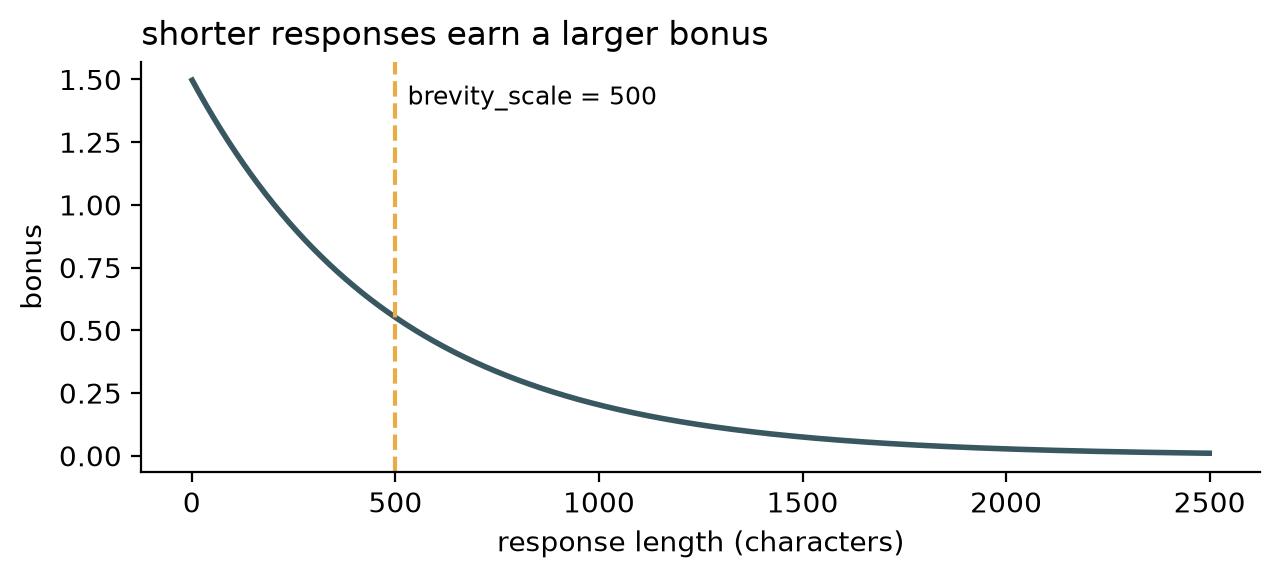

In [6]:
plot_brevity_bonus(brevity_scale=500)

Every score function in this notebook takes the prompt and the response and returns a number, higher is better. This one ignores the prompt, but keeping the signature uniform means any of them can be plugged into the same loop later.

In [7]:
def heuristic_score(prompt, text, brevity_scale=500.0):
    score = 0.0
    if last_boxed(text) is not None:
        score += 2.0  # a boxed final answer, the format we asked for
    elif NUMBER.search(text):
        score += 1.0  # no box, but at least a number to extract
    score += 1.5 * math.exp(-len(text) / brevity_scale)  # a brevity bonus that decays with length
    return score

In [8]:
print(heuristic_score(prompt_cot, solution_a))
print(heuristic_score(prompt_cot, solution_b))

2.2243529288339525
2.0930577610660377


Both solutions box their answer, so the brevity term decides, and the shorter one wins. The score knows nothing about rectangles. It is a format filter, useful for throwing out responses that never reached an answer, and it will stay useful as a baseline for the next, smarter score.

> **Try it.** Score the string `"\\boxed{126}"` on its own. It beats both worked solutions by a wide margin. That is the weakness of any rule that rewards brevity: it prefers a bare guess to a worked answer.

## `Step 4`: What the model thinks of its own text

A language model does more than pick the next token. At every position it produces a probability for *every* token in the vocabulary, and when the text is already written we can read off the probability it gave to the token that actually came next. One forward pass over the whole text returns one row of logits per position; a softmax turns each row into probabilities; then we pick, at position *t*, the probability of token *t + 1*.

In [9]:
@torch.inference_mode()
def token_probs(model, tokenizer, text, device):
    token_ids = torch.tensor(tokenizer.encode(text), device=device)
    logits = model(token_ids.unsqueeze(0)).squeeze(0).float()
    probs = torch.softmax(logits, dim=-1)
    positions = torch.arange(len(token_ids) - 1, device=device)  # position t predicts token t + 1
    next_ids = token_ids[1:]
    return probs[positions, next_ids]

In [10]:
text = "The largest planet in the solar system is Jupiter"
token_ids = tokenizer.encode(text)

probs = token_probs(model, tokenizer, text, device)
for token_id, p in zip(token_ids[1:], probs.tolist()):
    print(repr(tokenizer.decode([token_id])), round(p, 4))

' largest' 0.0007
' planet' 0.0072
' in' 0.8545
' the' 0.3172
' solar' 0.6999
' system' 0.997
' is' 0.7408
' Jupiter' 0.1179


Read down the list. After "The" the model gives "largest" less than one percent, because almost anything can follow "The". After "the solar" it gives "system" more than 99 percent. The last token, "Jupiter", gets about twelve percent: the model knows the fact, but a dozen other continuations were also plausible. The first token of the text has no entry at all. Nothing comes before it, so there is no prediction to score.

The probability of the whole text, under the model, is the product of these numbers (the chain rule of probability: each token is predicted given all the tokens before it). Swap the last word and only the last factor changes:

In [11]:
for ending in ["Jupiter", "Saturn", "Tuesday"]:
    probs = token_probs(model, tokenizer, "The largest planet in the solar system is " + ending, device)
    print(ending, "last token:", round(probs[-1].item(), 8), "product:", probs.prod().item())

Jupiter last token: 0.11785185 product: 8.937797701946693e-08
Saturn last token: 0.0140754 product: 1.067467625404106e-08
Tuesday last token: 3.9e-07 product: 2.939426859468325e-13


The ordering is what we hoped for. The numbers are not: the product of eight probabilities is already around a hundred-millionth, and a solution of four hundred tokens would multiply four hundred of them. The result underflows to zero long before that. The fix is the oldest one in statistics.

## `Step 5`: Log-probabilities

Take the logarithm. A product of probabilities becomes a sum of log-probabilities, every term is a modest negative number, and nothing underflows. PyTorch provides [`torch.log_softmax`](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.log_softmax.html), which computes `log(softmax(x))` in one numerically careful step. On seven toy logits:

In [12]:
toy_logits = torch.linspace(-2, 2, steps=7)

print(torch.softmax(toy_logits, dim=-1))
print(torch.log(torch.softmax(toy_logits, dim=-1)))
print(torch.log_softmax(toy_logits, dim=-1))

tensor([0.0090, 0.0175, 0.0341, 0.0665, 0.1295, 0.2522, 0.4912])
tensor([-4.7109, -4.0442, -3.3776, -2.7109, -2.0442, -1.3776, -0.7109])
tensor([-4.7109, -4.0442, -3.3776, -2.7109, -2.0442, -1.3776, -0.7109])


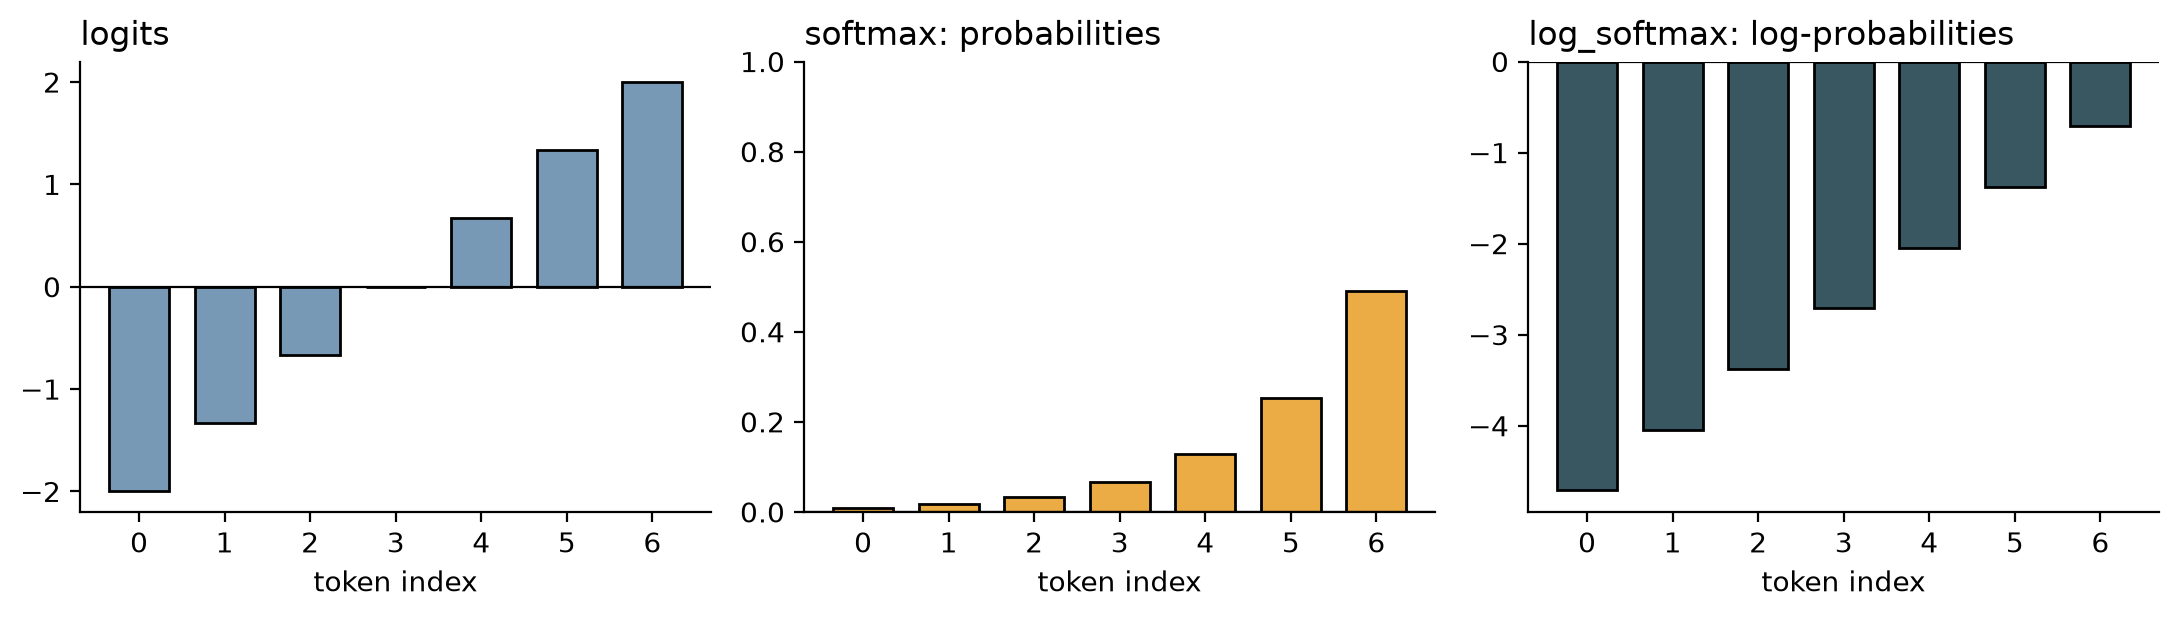

In [13]:
plot_logits_to_logprobs(toy_logits)

Three views of the same row. The softmax squeezes everything into (0, 1) and the small values become hard to tell apart; the log-softmax spreads them out again, with the most likely token nearest zero. `token_probs` with the softmax swapped for a log-softmax and the product for a sum:

In [14]:
@torch.inference_mode()
def token_logprobs(model, tokenizer, text, device):
    token_ids = torch.tensor(tokenizer.encode(text), device=device)
    logits = model(token_ids.unsqueeze(0)).squeeze(0).float()
    logprobs = torch.log_softmax(logits, dim=-1)
    positions = torch.arange(len(token_ids) - 1, device=device)  # position t predicts token t + 1
    next_ids = token_ids[1:]
    return logprobs[positions, next_ids]

In [15]:
for ending in ["Jupiter", "Saturn", "Tuesday"]:
    logprobs = token_logprobs(model, tokenizer, "The largest planet in the solar system is " + ending, device)
    print(ending, "last token:", round(logprobs[-1].item(), 2), "sum:", round(logprobs.sum().item(), 2))

Jupiter last token: -2.14 sum: -16.23
Saturn last token: -4.26 sum: -18.36
Tuesday last token: -14.76 sum: -28.86


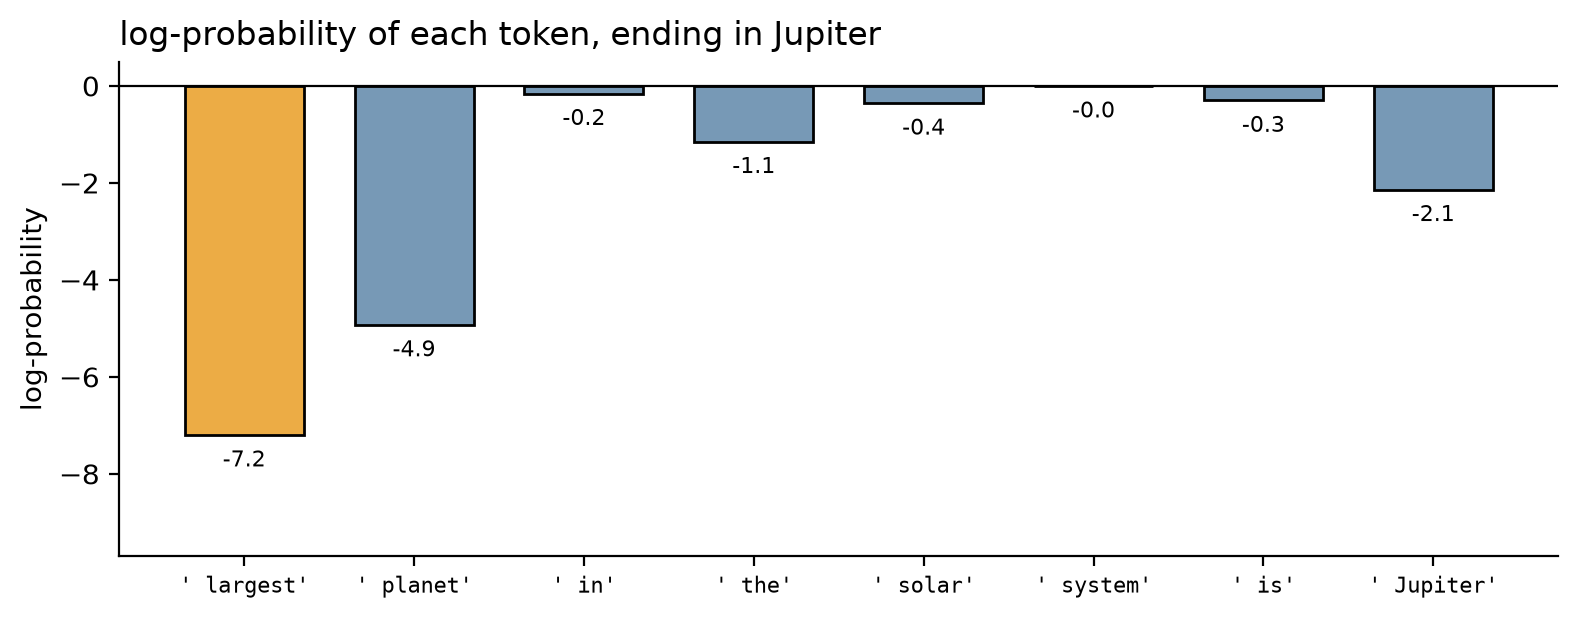

In [16]:
tokens = [tokenizer.decode([i]) for i in token_ids[1:]]
plot_token_logprobs(tokens, token_logprobs(model, tokenizer, text, device), title="log-probability of each token, ending in Jupiter")

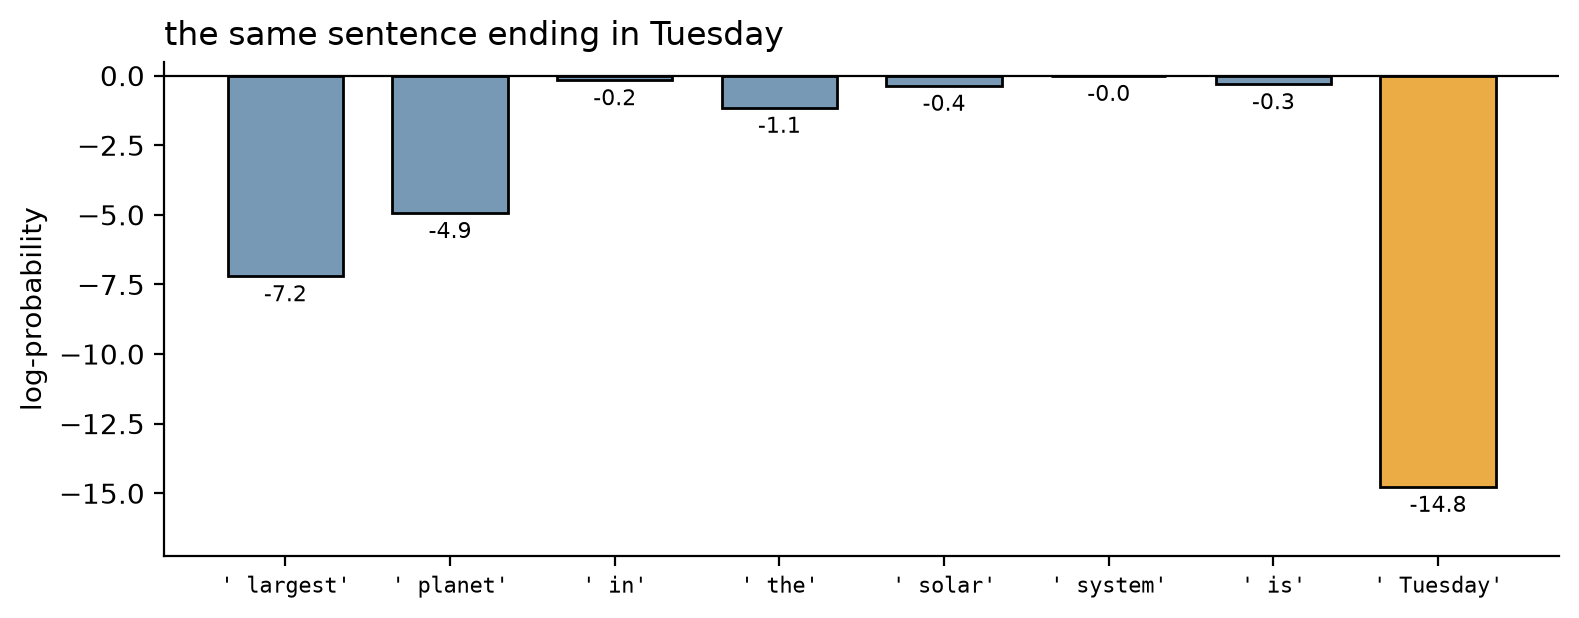

In [17]:
plot_token_logprobs(tokens[:-1] + [" Tuesday"], token_logprobs(model, tokenizer, text.replace("Jupiter", "Tuesday"), device), title="the same sentence ending in Tuesday")

Same sentence, one bar changes. A log-probability of minus fifteen means the model would produce "Tuesday" there about once in three million tries. These per-token numbers are the raw material of everything that follows, including the training loss in the next stage of the track.

## `Step 6`: Confidence as a score

Two adjustments turn the sum into a score for a *response*. First, only the response tokens count: the prompt was given to the model, so its probabilities say nothing about the answer. Second, average instead of summing, so that a long solution is not punished for having more tokens. The result is the average log-probability of the answer given the prompt, the model's **confidence** in its own text.

The prompt and the answer are encoded separately so that we know where one ends and the other begins. The position just before the first answer token is the one that predicts it, so the scored positions start there.

In [18]:
@torch.inference_mode()
def avg_logprob(model, tokenizer, prompt, answer, device):
    prompt_ids = tokenizer.encode(prompt)
    answer_ids = tokenizer.encode(answer)
    if not answer_ids:
        return float("-inf")  # an empty answer is the least confident answer there is
    token_ids = torch.tensor(prompt_ids + answer_ids, device=device)

    logits = model(token_ids.unsqueeze(0)).squeeze(0).float()
    logprobs = torch.log_softmax(logits, dim=-1)

    start = len(prompt_ids) - 1  # the position that predicts the first answer token
    positions = torch.arange(start, len(token_ids) - 1, device=device)
    next_ids = token_ids[start + 1:]
    return logprobs[positions, next_ids].mean().item()

In [19]:
question = "Which planet is the largest in the solar system?"

print(avg_logprob(model, tokenizer, question, " The largest planet is Jupiter.", device))
print(avg_logprob(model, tokenizer, question, " The largest planet is Saturn.", device))
print(avg_logprob(model, tokenizer, question, " The largest planet is Tuesday.", device))

-1.968900442123413
-2.6026370525360107
-5.2826433181762695


Wrapped to the same `(prompt, text)` signature as the rule-based score, with the model, the tokenizer, and the device fixed, it can score the two solutions from Step 2:

In [20]:
def confidence_score(prompt, text):
    return avg_logprob(model, tokenizer, prompt, text, device)

In [21]:
print(confidence_score(prompt_cot, solution_a))
print(confidence_score(prompt_cot, solution_b))

-0.07452233880758286
-0.16620323061943054


The right solution is also the more confident one. That is not a law. A model can be confidently wrong, and a base model's confidence is about how *familiar* the text looks, not about whether the arithmetic holds. But across many solutions the two correlate, which is enough for a score to be useful.

### Best-of-n

The first use of a score needs no new generation at all. Sample several solutions, as self-consistency did, but instead of letting them vote, keep the one the score likes best. This is **best-of-n** selection, and with a strong scorer it is one of the most effective inference-time methods there is.

```mermaid
flowchart LR
    P[prompt] --> S1[sample 1]
    P --> S2[sample 2]
    P --> S3[sample n]
    S1 --> C1[score]
    S2 --> C2[score]
    S3 --> C3[score]
    C1 --> B{highest}
    C2 --> B
    C3 --> B
    B --> F[the best sample]
    style P fill:#C3D6E7,stroke:#000
    style B fill:#CEEB13,stroke:#000
    style F fill:#ECAC45,stroke:#000
```

In [22]:
def best_of_n(model, tokenizer, prompt, device, score_fn, n_samples=5, temperature=0.8, top_p=0.9, max_new_tokens=1024, verbose=False):
    completions, scores = [], []
    for i in range(n_samples):
        text = generate_text(model, tokenizer, prompt, device, max_new_tokens=max_new_tokens, temperature=temperature, top_p=top_p)
        completions.append(text)
        scores.append(score_fn(prompt, text))
        if verbose:
            print(f"sample {i + 1}/{n_samples}: score {scores[-1]:.3f}")

    best = max(range(n_samples), key=lambda i: scores[i])
    return {"completions": completions, "scores": scores, "best": best, "final": completions[best]}

In [23]:
torch.manual_seed(2)
pick = best_of_n(model, tokenizer, prompt_cot, device, confidence_score, n_samples=5, max_new_tokens=600, verbose=True)

for text, score in zip(pick["completions"], pick["scores"]):
    print(repr(extract_final_answer(text)), "with confidence", round(score, 3))
print("picked:", repr(extract_final_answer(pick["final"])), grade(extract_final_answer(pick["final"]), answer))

sample 1/5: score -0.075
sample 2/5: score -0.157
sample 3/5: score -0.202
sample 4/5: score -0.164
sample 5/5: score -0.050
'126' with confidence -0.075
'126' with confidence -0.157
'126' with confidence -0.202
'126' with confidence -0.164
'126' with confidence -0.05
picked: '126' True


When we ran this, all five chains reached 126, so any selection rule would have picked a right answer. Look at the scores anyway: they spread over a factor of four for five chains that agree on the result. The vote in the previous notebook could only count those chains; a scorer ranks them, and when chains disagree it can pick a minority answer, for better or worse. The benchmark in Step 9 measures which happens more often.

> **Try it.** Run `best_of_n` with `heuristic_score` instead. Does the rule-based score pick the same chain?

## `Step 7`: Critique and revise

Now the third lever itself. Three prompts, three generations: the model drafts a solution, is shown the draft and asked to critique it, then is shown the draft and the critique and asked to rewrite. Two templates do the asking. Like `MATH_PROMPT` they are filled with a plain `replace`, so the braces in `\\boxed{ANSWER}` survive.

In [24]:
CRITIQUE_PROMPT = (
    "You are checking a solution to a math problem. Point out any mistake in the reasoning or the arithmetic, "
    "or say that the solution is correct. Then give a short plan for fixing it.\n\n"
    "Question:\n{problem}\n\nSolution:\n{draft}\n\nCritique (at most 100 words):"
)

REFINE_PROMPT = (
    "Rewrite the solution using the critique. Show the corrected steps and write the final result "
    "on a new line as:\n\\boxed{ANSWER}\n\n"
    "Question:\n{problem}\n\nSolution:\n{draft}\n\nCritique:\n{critique}\n\nRevised solution:"
)


def render_critique_prompt(problem, draft):
    return CRITIQUE_PROMPT.replace("{problem}", problem).replace("{draft}", draft.strip())


def render_refine_prompt(problem, draft, critique):
    return REFINE_PROMPT.replace("{problem}", problem).replace("{draft}", draft.strip()).replace("{critique}", critique.strip())

The draft uses the plain prompt, without the step-by-step sentence, and a little randomness (temperature 0.7, top-p 0.9), the settings the benchmark will use too:

In [25]:
torch.manual_seed(6)
draft = generate_text(model, tokenizer, prompt, device, max_new_tokens=400, stream=True, temperature=0.7, top_p=0.9)

 120

In [26]:
grade(extract_final_answer(draft), answer)

False

A bare guess, and a wrong one. The critique prompt shows the model its own draft:

In [27]:
critique = generate_text(model, tokenizer, render_critique_prompt(problem, draft), device, max_new_tokens=256, stream=True, temperature=0.7, top_p=0.9)

 The solution is correct, but the plan to fix it is not clear. The problem should specify the units of measurement for the length and width, as well as the units of measurement for the perimeter. Additionally, the equation for the perimeter should be (2L + 2W) = 50, where L is the length and W is the width. Finally, the area of the rectangle should be L * W, where L is the length and W is the width.

In [28]:
revised = generate_text(model, tokenizer, render_refine_prompt(problem, draft, critique), device, max_new_tokens=400, stream=True, temperature=0.7, top_p=0.9)

 
1. Let L be the length and W be the width of the rectangle.
2. According to the problem, the length is 4 more than twice the width, so we can write L = 2W + 4.
3. The perimeter of a rectangle is given by P = 2L + 2W. Given that the perimeter is 50, we can write 2L + 2W = 50.
4. Substitute the expression for L from step 2 into the equation for the perimeter: 2(2W + 4) + 2W = 50.
5. Simplify the equation: 4W + 8 + 2W = 50.
6. Combine like terms: 6W + 8 = 50.
7. Subtract 8 from both sides: 6W = 42.
8. Divide both sides by 6: W = 7.
9. Substitute the value of W back into the equation for L: L = 2(7) + 4 = 18.
10. The area of a rectangle is given by A = L * W. Substitute the values of L and W into the equation: A = 18 * 7 = 126.

Final result:
126

In [29]:
grade(extract_final_answer(revised), answer)

True

Read the critique before celebrating. A 0.6B base model is a poor critic of itself: when we ran this it declared the wrong draft correct, then wandered into advice about units and formulas. What actually fixed the answer was the rewrite prompt. Asked to "show the corrected steps", the model worked the problem through, which the draft prompt never asked it to do. That is the honest picture of self-refinement on a small model. The critique step is weak, and much of the gain comes from the rewrite being a worked solution.

Now the two scores look at the draft and the revision:

In [30]:
print("rule-based:", round(heuristic_score(prompt, draft), 3), "->", round(heuristic_score(prompt, revised), 3))
print("confidence:", round(confidence_score(prompt, draft), 3), "->", round(confidence_score(prompt, revised), 3))

rule-based: 2.488 -> 1.332
confidence: -1.21 -> -0.186


They disagree. The rule-based score prefers the draft: it is boxed and short. The confidence score prefers the revision by a wide margin: a worked solution is text the model finds far more familiar than a bare number after "Answer:". Which score sits in the loop decides which answer comes out of it.

## `Step 8`: The refinement loop

Put the three generations in a loop and let a score be the gatekeeper: after each critique and rewrite, keep the revision only if it scores at least as well as the text it would replace. Without a score every revision is kept. One more rule, learned the hard way: when the critique finds nothing to fix, the model often has nothing to say after "Revised solution:" and stops immediately, so an empty revision is never kept.

<div align="center"><img src="assets/self-refinement.gif" alt="Animation of one refinement iteration on the rectangle problem: the draft answers 120, the critique is generated, the rewrite works the problem through to 126, and the two scores judge the rewrite differently, the rule-based score rejecting it and the confidence score accepting it" width="900"/></div>

```mermaid
flowchart LR
    D[draft] --> C[critique]
    C --> R[rewrite]
    R --> G{score at least\nas high?}
    G -- yes --> K[keep the rewrite]
    G -- no --> X[keep the draft]
    K --> N{more\niterations?}
    X --> N
    N -- yes --> C
    N -- no --> F[final answer]
    style D fill:#C3D6E7,stroke:#000
    style G fill:#CEEB13,stroke:#000
    style F fill:#ECAC45,stroke:#000
```

In [31]:
def self_refine(model, tokenizer, problem, device, iterations=1, score_fn=None, template=MATH_PROMPT, max_new_tokens=1024, max_critique_tokens=256, temperature=0.7, top_p=0.9, verbose=False):
    prompt = render_math_prompt(problem, template)
    current = generate_text(model, tokenizer, prompt, device, max_new_tokens=max_new_tokens, temperature=temperature, top_p=top_p)
    current_score = score_fn(prompt, current) if score_fn else 0.0
    generated = [current]
    steps = []

    for it in range(iterations):
        critique = generate_text(model, tokenizer, render_critique_prompt(problem, current), device, max_new_tokens=max_critique_tokens, temperature=temperature, top_p=top_p)
        revised = generate_text(model, tokenizer, render_refine_prompt(problem, current, critique), device, max_new_tokens=max_new_tokens, temperature=temperature, top_p=top_p)
        revised_score = score_fn(prompt, revised) if score_fn else 0.0
        generated += [critique, revised]
        steps.append({"draft": current, "critique": critique, "revised": revised, "score_before": current_score, "score_after": revised_score})
        if verbose:
            print(f"iteration {it + 1}: {extract_final_answer(current)!r} -> {extract_final_answer(revised)!r},", f"score {current_score:.3f} -> {revised_score:.3f}")
        if revised.strip() and revised_score >= current_score:  # keep it unless empty or scored worse
            current, current_score = revised, revised_score

    return {"final": current, "answer": extract_final_answer(current), "steps": steps, "generated": generated}

The same seed as Step 7, so the draft, the critique, and the rewrite are the ones above, now with two iterations and the confidence score at the gate:

In [32]:
torch.manual_seed(6)
refined = self_refine(model, tokenizer, problem, device, iterations=2, score_fn=confidence_score, max_new_tokens=400, verbose=True)
print(refined["answer"], grade(refined["answer"], answer))

iteration 1: '120' -> '126', score -1.210 -> -0.186
iteration 2: '126' -> '', score -0.186 -> -inf
126 True


In [33]:
torch.manual_seed(6)
refined_rules = self_refine(model, tokenizer, problem, device, iterations=2, score_fn=heuristic_score, max_new_tokens=400, verbose=True)
print(refined_rules["answer"], grade(refined_rules["answer"], answer))

iteration 1: '120' -> '126', score 2.488 -> 1.332
iteration 2: '120' -> '120', score 2.488 -> 2.488
120 False


Same draft, same critique, same rewrite, two different final answers, because the two scores judged the rewrite differently. The loop is only as good as its gatekeeper.

> **Try it.** Run the loop with `score_fn=None` and look at `refined["steps"]`. Then try a different seed: how often does the critique say the draft is correct when it is not?

## `Step 9`: Measure it

`evaluate_math` from the math verifier notebook, imported from `reasoning_utils`, gained three arguments for this notebook: `score_fn` is any of the `(prompt, text)` functions above; `select="best"` makes several samples per problem a best-of-n pick instead of a vote; and `refine_iterations` runs the critique-and-rewrite loop on each problem. The generate-and-extract step became:

```python
if refine_iterations > 0:
    refined = self_refine(model, tokenizer, row["problem"], device, refine_iterations, score_fn, template, ...)
    completion, predicted = refined["final"], refined["answer"]
elif n_samples == 1:
    ...                                         # one generation, as before
elif select == "best":
    pick = best_of_n(model, tokenizer, prompt, device, score_fn, n_samples, temperature, top_p, ...)
    predicted = extract_final_answer(pick["final"])
else:
    vote = self_consistency(...)                # the vote, as before
```

The token count includes every draft, critique, and rewrite, which is the real cost. Same fifty problems as before. The greedy baseline and the vote of five are rerun here so that every bar in the chart comes from the same session.

In [34]:
N = 50
subset = load_math500()[:N]

results = {}
print("greedy")
results["greedy"] = evaluate_math(model, tokenizer, device, subset, max_new_tokens=1024)

greedy
10/50 correct so far: 3
20/50 correct so far: 5
30/50 correct so far: 5
40/50 correct so far: 8
50/50 correct so far: 10
accuracy: 20.0% (10/50)
average response: 110 tokens
time: 0.4 min


In [35]:
torch.manual_seed(0)
print("refine once, no score")
results["refine once, no score"] = evaluate_math(model, tokenizer, device, subset, max_new_tokens=1024, temperature=0.7, top_p=0.9, refine_iterations=1)

refine once, no score
10/50 correct so far: 3
20/50 correct so far: 6
30/50 correct so far: 6
40/50 correct so far: 7
50/50 correct so far: 9
accuracy: 18.0% (9/50)
average response: 329 tokens
time: 1.2 min


In [36]:
torch.manual_seed(0)
print("refine once, rule-based score")
results["refine once, rule-based score"] = evaluate_math(model, tokenizer, device, subset, max_new_tokens=1024, temperature=0.7, top_p=0.9, refine_iterations=1, score_fn=heuristic_score)

refine once, rule-based score
10/50 correct so far: 3
20/50 correct so far: 5
30/50 correct so far: 5
40/50 correct so far: 6
50/50 correct so far: 9
accuracy: 18.0% (9/50)
average response: 329 tokens
time: 1.2 min


In [37]:
torch.manual_seed(0)
print("refine once, confidence score")
results["refine once, confidence score"] = evaluate_math(model, tokenizer, device, subset, max_new_tokens=1024, temperature=0.7, top_p=0.9, refine_iterations=1, score_fn=confidence_score)

refine once, confidence score
10/50 correct so far: 3
20/50 correct so far: 6
30/50 correct so far: 6
40/50 correct so far: 7
50/50 correct so far: 9
accuracy: 18.0% (9/50)
average response: 329 tokens
time: 1.2 min


The three refinement runs share a seed, so they draft, critique, and rewrite the very same texts. Only the gate differs. The last two runs are the step-by-step prompt with five sampled chains per problem, picked by vote and picked by confidence:

In [38]:
torch.manual_seed(0)
print("step by step, vote of 5")
results["step by step, vote of 5"] = evaluate_math(model, tokenizer, device, subset, max_new_tokens=1024, template=COT_PROMPT, temperature=0.8, top_p=0.9, n_samples=5)

step by step, vote of 5
10/50 correct so far: 4
20/50 correct so far: 6
30/50 correct so far: 9
40/50 correct so far: 15
50/50 correct so far: 20
accuracy: 40.0% (20/50)
average response: 2496 tokens
time: 8.9 min


In [39]:
torch.manual_seed(0)
print("step by step, best of 5 by confidence")
results["step by step, best of 5 by confidence"] = evaluate_math(model, tokenizer, device, subset, max_new_tokens=1024, template=COT_PROMPT, temperature=0.8, top_p=0.9, n_samples=5, select="best", score_fn=confidence_score)

step by step, best of 5 by confidence
10/50 correct so far: 6
20/50 correct so far: 9
30/50 correct so far: 13
40/50 correct so far: 19
50/50 correct so far: 25
accuracy: 50.0% (25/50)
average response: 2496 tokens
time: 9.0 min


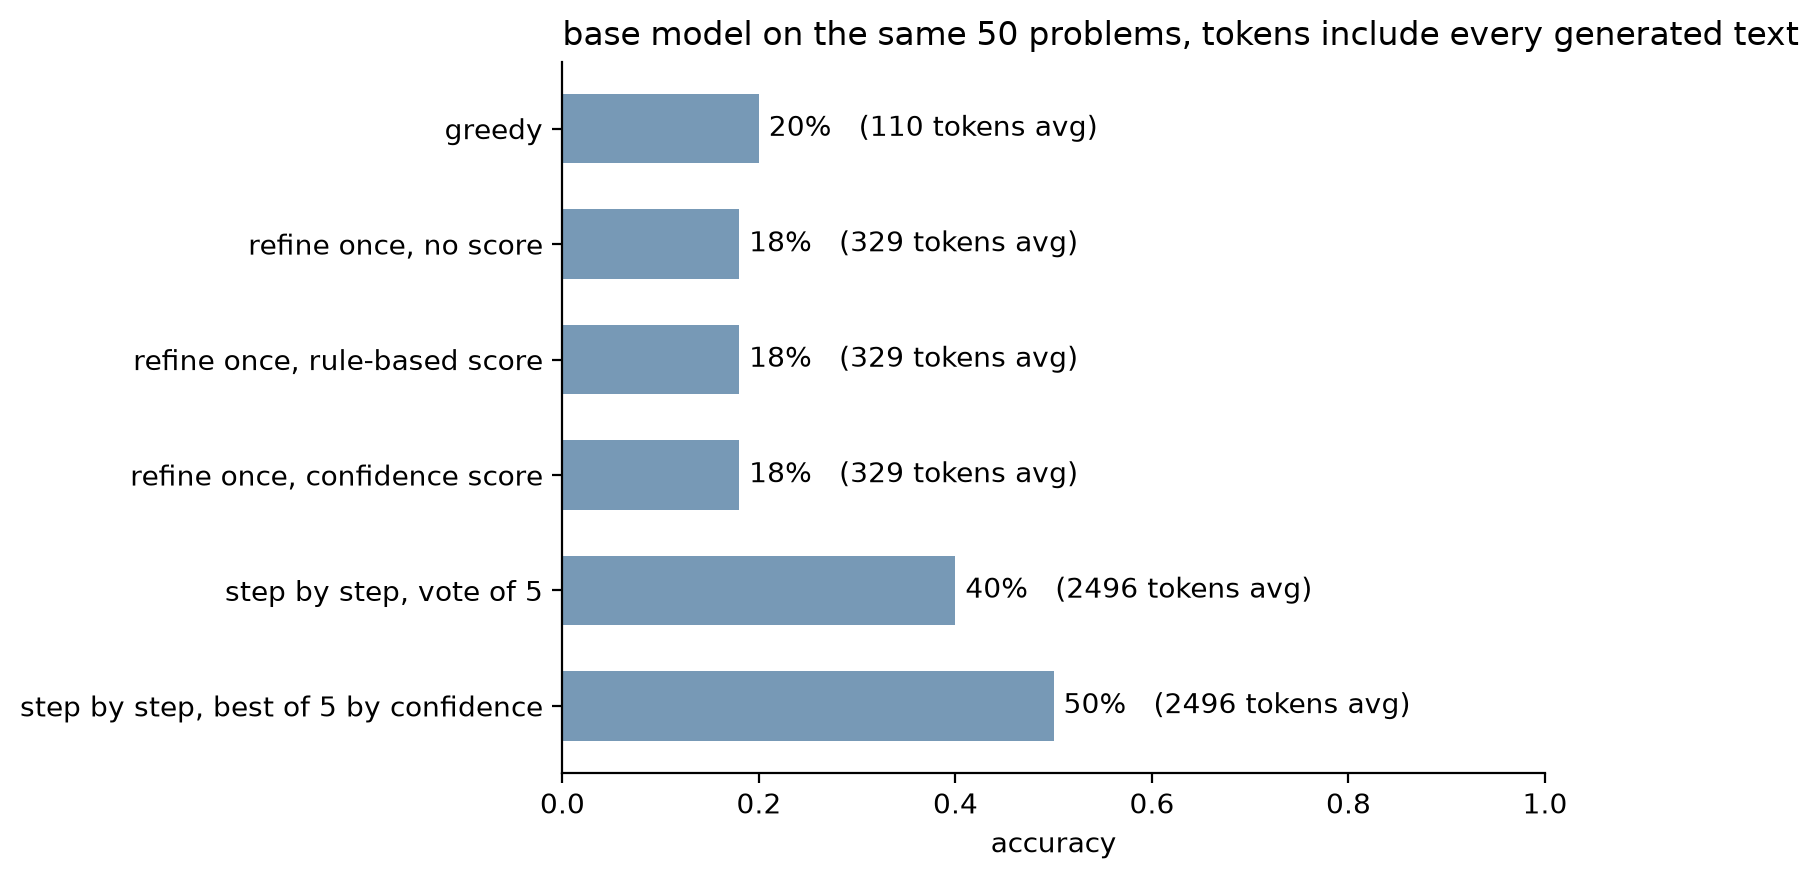

In [40]:
plot_accuracy_comparison(results, title=f"base model on the same {N} problems, tokens include every generated text")

Two findings, one disappointing and one not.

**Self-refinement did not help this model.** All three refinement runs landed slightly below the greedy baseline, at three times the tokens. They share every draft, critique, and rewrite, so the gate is the only difference between them, and no gate turned the method into a win: the rule-based score kept short wrong drafts, the confidence score kept long wrong rewrites, and the no-score run kept whichever came last. The single example in Step 7 was a real effect, a wrong guess rewritten into a worked solution, but on fifty problems the critique step misjudged the draft about as often as it helped, which is the finding of the self-correction literature in the further reading: a model that cannot solve a problem usually cannot tell that its solution is wrong either. Refinement earns its tokens with a stronger critic, a verifier in the loop, or a model that was trained to check its work.

**Best-of-n beat the vote.** The last two bars used identical chains, identical tokens, and different selection rules, and ranking by confidence solved more problems than counting answers. Where the five chains disagreed, the most confident one was right more often than the most common one. That is a small base model, a single seed, and fifty problems, so treat the gap as a hint rather than a law, but it is the hint that every reward-model and verifier-guided search method builds on: a score that reads the chain can beat a rule that only reads the final answer.

The vote itself came out a few points lower than in the previous notebook, under the same seed and settings. Compiled kernels and the extra scoring passes change the arithmetic in the last decimal places, which is enough to change a sampled token here and there, and fifty problems turn that into several points. The ordering of the methods is the result; the exact percentages are not.

## `Step 10`: Promote it to the toolbox

`heuristic_score`, `token_logprobs`, `avg_logprob`, and `best_of_n` now live in `reasoning_utils/scoring.py`, and the two prompt templates with `self_refine` in `reasoning_utils/refine.py`, exactly as written above. `scripts/evaluate_math500.py` exposes them as `--score`, `--select`, and `--refine`, so the full benchmark can be run from the command line.

In [41]:
from reasoning_utils import REFINE_PROMPT as REFINE_PROMPT_TOOLBOX
from reasoning_utils import heuristic_score as heuristic_score_toolbox

print(REFINE_PROMPT_TOOLBOX == REFINE_PROMPT)
print(heuristic_score_toolbox(prompt_cot, solution_a) == heuristic_score(prompt_cot, solution_a))

True
True


## Summary

- Choosing among solutions, or deciding whether a rewrite is better, needs a score that works without the reference answer. A rule-based score reads the shape of the text; the model's confidence reads the probabilities it gave its own tokens.
- A text's probability under the model is the product of its per-token probabilities. Products of small numbers underflow, so everything is done with log-probabilities, which turn the product into a sum. `log_softmax` gives them directly.
- Confidence is the average log-probability of the response tokens given the prompt. It correlates with correctness, loosely, and a base model can be confidently wrong.
- Best-of-n samples several chains and keeps the highest-scoring one. Self-refinement drafts, critiques, and rewrites, with the score deciding whether each rewrite is kept.
- A small base model is a poor critic of itself. Most of the refinement gain comes from the rewrite being a worked solution, and a weak gatekeeper can throw that gain away.
- The verifier remains the judge of all of it. In the next stage the verifier becomes the reward, and the per-token log-probabilities from this notebook become the thing that training pushes on.

## Further reading

- [Self-Refine: Iterative Refinement with Self-Feedback](https://arxiv.org/abs/2303.17651) (Madaan et al., 2023), the critique-and-revise loop
- [Large Language Models Cannot Self-Correct Reasoning Yet](https://arxiv.org/abs/2310.01798) (Huang et al., 2023), on why the critique step is the weak link
- [Training Verifiers to Solve Math Word Problems](https://arxiv.org/abs/2110.14168) (Cobbe et al., 2021), best-of-n with a trained verifier
- [Let's Verify Step by Step](https://arxiv.org/abs/2305.20050) (Lightman et al., 2023), scoring each step instead of the whole response
- [Scaling LLM Test-Time Compute Optimally Can Be More Effective Than Scaling Model Parameters](https://arxiv.org/abs/2408.03314) (Snell et al., 2024), when revision beats sampling and when it does not
- [`torch.log_softmax`](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.log_softmax.html) documentation

Next up in this track: training. The verifier becomes a reward, the log-probabilities become a loss, and GRPO changes the weights.